# Modelo: arquitectura, entrenamiento y evaluación

Proyecto final — Tecnicatura en Ciencias de Datos. Bimestre 1 (local).

**Objetivo.** Mostrar el modelo entrenado y sus resultados. El entrenamiento no se ejecuta
en este notebook: se corrió con `python -m src.models.train`, porque SageMaker requiere un
script. Acá se carga el modelo ya guardado y se reutilizan las funciones de `src/`, sin
duplicar código.

| Sección | Qué muestra |
|---|---|
| 1. El modelo | Qué partes vienen preentrenadas, cuál se entrenó y cómo recorre una imagen |
| 2. El entrenamiento | Cómo evolucionó época por época y por qué se conservó la época 15 |
| 3. La evaluación | Qué imágenes de test se excluyen y por qué, y los resultados sobre el resto |
| 4. Los errores | Qué imágenes falla el modelo y con cuánta seguridad |
| 5. La prueba de brillo | Si el modelo usa el brillo de la imagen como atajo |

---
## 0. Setup

Mismo setup que los notebooks anteriores. Requiere `models/model.pth`, que se genera con
`train.py` y no se versiona.

`evaluate.py` configura matplotlib para ejecutarse sin pantalla, como en SageMaker. La línea
`%matplotlib inline`, posterior a los imports, vuelve a habilitar los gráficos en el
notebook.

In [1]:
import json
from pathlib import Path
import sys

REPO_DIR = str(Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd())
if REPO_DIR not in sys.path:
    sys.path.insert(0, REPO_DIR)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch.utils.data import DataLoader
from dotenv import load_dotenv
from PIL import Image

from src.data import eda
from src.data.augmentation import get_eval_pipeline
from src.data.dataset import CLASES, MRIDataset
from src.data.preprocessing import split_dataset
from src.data.similitud import UMBRAL_COPIA, vectores_de_comparacion
from src.models.architecture import build_model
from src.models.evaluate import (
    brightness_stress_test,
    cargar_modelo,
    compute_metrics,
    plot_brightness_stress_test,
    plot_confusion_matrix,
    predecir,
    sensibilidad_al_umbral,
)

%matplotlib inline
plt.rcParams["figure.dpi"] = 110
MODEL_DIR = Path(REPO_DIR) / "models"

In [2]:
load_dotenv(Path(REPO_DIR) / ".env")
import kagglehub

ruta_dataset = kagglehub.dataset_download("masoudnickparvar/brain-tumor-mri-dataset")
df_train, df_val, df_test = split_dataset(eda.listar_imagenes(ruta_dataset))
print(f"train: {len(df_train):,} | val: {len(df_val):,} | test: {len(df_test):,}")

train: 4,909 | val: 701 | test: 1,403


---
## 1. El modelo

EfficientNet-B0 fue entrenada previamente con más de un millón de fotografías generales
(ImageNet). Ese entrenamiento le permite reconocer patrones visuales: bordes, texturas y
formas. El proyecto reutiliza ese conocimiento y solo entrena la última capa, que decide a
cuál de las 4 clases corresponde una imagen (*transfer learning* con el backbone congelado).

### 1.1 Qué se entrenó y qué no

Un **parámetro** es un número interno que el modelo ajusta al aprender. En PyTorch, el
atributo `requires_grad` indica si ese número puede modificarse durante el
entrenamiento.

In [3]:
model = cargar_modelo(MODEL_DIR)
model.eval()

partes = {
    "features (backbone)": model.features,
    "avgpool": model.avgpool,
    "classifier (capa final)": model.classifier,
}
tabla = pd.DataFrame(
    {
        nombre: {
            "parámetros": sum(p.numel() for p in parte.parameters()),
            "entrenables": sum(p.numel() for p in parte.parameters() if p.requires_grad),
        }
        for nombre, parte in partes.items()
    }
).T
tabla.loc["TOTAL"] = tabla.sum()
print(f"Entrenables: {tabla.loc['TOTAL', 'entrenables'] / tabla.loc['TOTAL', 'parámetros']:.2%} del total")
tabla

Entrenables: 0.13% del total


,parámetros,entrenables
features (backbone),4007548,0
avgpool,0,0
classifier (capa final),5124,5124
TOTAL,4012672,5124


**Lectura.** Solo se entrenan 5.124 de los 4.012.672 parámetros. El número surge de la capa
final: recibe 1.280 valores y produce 4 puntajes, es decir 1.280 × 4 pesos más 4 términos
independientes (uno por clase). Por eso el entrenamiento es viable en CPU.

### 1.2 Verificación: el backbone no cambió

Que el backbone esté configurado como congelado no demuestra que haya quedado intacto. Sus
capas BatchNorm también guardan estadísticas que pueden actualizarse aunque los pesos estén
fijos; `train.modo_entrenamiento()` lo evita. Para comprobarlo, comparo cada valor del
backbone entrenado con el original de ImageNet.

In [4]:
original = build_model(num_classes=len(CLASES), pretrained=True).features.state_dict()
entrenado = model.features.state_dict()

distintos = [nombre for nombre in original if not torch.equal(original[nombre], entrenado[nombre])]
print(f"Componentes del backbone comparados: {len(original)}")
print(f"Componentes que cambiaron: {len(distintos)}")

Componentes del backbone comparados: 358
Componentes que cambiaron: 0


### 1.3 El recorrido de una imagen

Sigo una imagen de validación a través del modelo. Cada paso la resume: de una grilla de
píxeles a 4 puntajes, uno por clase. El modelo devuelve puntajes sin escala (*logits*); la
función *softmax* los convierte en probabilidades que suman 1.

In [5]:
ejemplo = df_val[df_val["clase"] == "glioma"].iloc[0]
imagen = Image.open(ejemplo["path"]).convert("RGB")
entrada = get_eval_pipeline()(imagen).unsqueeze(0)  # agrega la dimensión del batch: (1, 3, 224, 224)

with torch.no_grad():
    mapas = model.features(entrada)
    resumen = torch.flatten(model.avgpool(mapas), 1)
    logits = model.classifier(resumen)
    proba = torch.softmax(logits, dim=1)
    # El recorrido paso a paso tiene que dar lo mismo que llamar al modelo completo.
    assert torch.allclose(logits, model(entrada))

pd.DataFrame(
    [
        ("Imagen de entrada", tuple(entrada.shape), "1 imagen, 3 canales, 224 × 224 píxeles"),
        ("Después de features", tuple(mapas.shape), "1.280 mapas de patrones de 7 × 7"),
        ("Después de avgpool", tuple(resumen.shape), "Cada mapa resumido en un número"),
        ("Después de classifier", tuple(logits.shape), "Un puntaje por clase"),
    ],
    columns=["Paso", "Forma", "Significado"],
)

,Paso,Forma,Significado
0,Imagen de entrada,"(1, 3, 224, 224)","1 imagen, 3 canales, 224 × 224 píxeles"
1,Después de features,"(1, 1280, 7, 7)",1.280 mapas de patrones de 7 × 7
2,Después de avgpool,"(1, 1280)",Cada mapa resumido en un número
3,Después de classifier,"(1, 4)",Un puntaje por clase


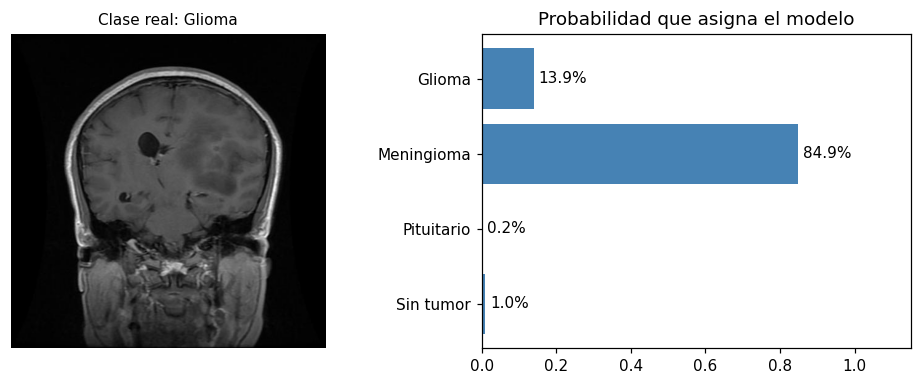

In [6]:
fig, (ax_img, ax_proba) = plt.subplots(1, 2, figsize=(9, 3.6))
ax_img.imshow(imagen)
ax_img.set_title(f"Clase real: {eda.ETIQUETAS[ejemplo['clase']]}", fontsize=10)
ax_img.axis("off")

barras = ax_proba.barh([eda.ETIQUETAS[c] for c in CLASES], proba[0].tolist(), color="steelblue")
ax_proba.bar_label(barras, labels=[f"{p:.1%}" for p in proba[0].tolist()], padding=3)
ax_proba.invert_yaxis()
ax_proba.set(title="Probabilidad que asigna el modelo", xlim=(0, 1.15))
plt.tight_layout()
plt.show()

**Lectura.** La clase con mayor probabilidad es la predicción. En este caso el modelo se
equivoca: es un glioma y le asigna 84,9% a meningioma, la confusión más frecuente del
proyecto (ver `docs/model_card.md`). Detecta que hay un tumor (1,0% para "Sin tumor"), pero
no acierta el tipo. También muestra que una probabilidad alta no garantiza una predicción
correcta.

Es un único caso, elegido por su posición en la lista y no por su resultado: ilustra el
mecanismo y no mide el desempeño del modelo.

---
## 2. El entrenamiento

Una **época** es una pasada completa por todas las imágenes de entrenamiento. Al final de
cada una, `train.py` mide el modelo sobre validación (imágenes que no usa para aprender) y
guarda el resultado en `historial.json`. Esta sección lee ese archivo; no vuelve a entrenar.

El entrenamiento se detiene cuando el **recall promedio de validación** no mejora durante 5
épocas seguidas (*early stopping*), y conserva el modelo de la mejor época, no el último.

In [7]:
historial = json.loads((MODEL_DIR / "historial.json").read_text(encoding="utf-8"))

curvas = pd.DataFrame(
    [
        {
            "época": h["epoca"],
            "loss train": h["loss_train"],
            "loss val": h["val"]["loss"],
            "recall val": h["val"]["recall_macro"],
            "glioma": h["val"]["recall_por_clase"]["glioma"],
            "meningioma": h["val"]["recall_por_clase"]["meningioma"],
            "tumores como sanos": h["val"]["tumores_como_sanos"],
        }
        for h in historial
    ]
).set_index("época")

mejor = curvas["recall val"].idxmax()
print(f"Épocas: {len(curvas)} | mejor: {mejor} | duración: {sum(h['segundos'] for h in historial) / 60:.0f} minutos")
curvas.round(3)

Épocas: 20 | mejor: 15 | duración: 52 minutos


,loss train,loss val,recall val,glioma,meningioma,tumores como sanos
época,,,,,,
1,0.640,0.399,0.870,0.844,0.708,7
2,0.416,0.331,0.893,0.860,0.758,6
3,0.371,0.301,0.892,0.866,0.742,6
4,0.347,0.279,0.906,0.849,0.815,3
5,0.334,0.268,0.914,0.832,0.854,3
6,0.317,0.253,0.915,0.866,0.837,3
7,0.302,0.251,0.916,0.804,0.910,3
8,0.293,0.246,0.912,0.799,0.871,6
9,0.283,0.243,0.916,0.860,0.837,6


### 2.1 ¿El modelo aprendió o memorizó?

La **loss** mide cuánto se equivoca el modelo: cuanto más baja, mejor. Si memorizara las
imágenes de entrenamiento (*sobreajuste*), la loss de train seguiría bajando mientras la de
validación empieza a subir.

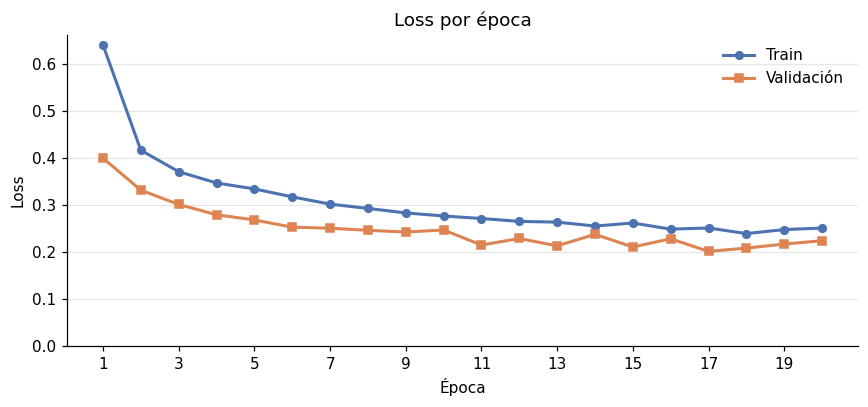

In [8]:
AZUL, NARANJA = "#4C72B0", "#DD8452"


def estilo(ax, titulo, eje_y):
    ax.set(title=titulo, xlabel="Época", ylabel=eje_y, xticks=range(1, len(curvas) + 1, 2))
    ax.grid(axis="y", color="0.9", linewidth=0.8)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)


fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(curvas["loss train"], color=AZUL, linewidth=2, marker="o", markersize=5, label="Train")
ax.plot(curvas["loss val"], color=NARANJA, linewidth=2, marker="s", markersize=5, label="Validación")
estilo(ax, "Loss por época", "Loss")
ax.set_ylim(0)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

**Lectura.** Las dos curvas bajan y terminan cerca una de la otra: no hay señales claras de
sobreajuste. Entre las épocas 17 y 20 la loss de validación sube levemente (de 0,201 a 0,224),
un movimiento similar a las oscilaciones de las épocas anteriores. Con solo 5.124 parámetros entrenables, el modelo tiene poca
capacidad para memorizar.

La loss de validación queda por debajo de la de train, al revés de lo habitual. Es esperable:
en train las imágenes llevan augmentation y la capa final usa Dropout, dos dificultades que no
se aplican en validación.

### 2.2 ¿Por qué la época 15?

Es la de mayor recall promedio en validación. Las 5 siguientes no la superaron y el
entrenamiento se cortó en la 20.

La validación tiene unas 175 imágenes por clase, por lo que cada valor tiene un margen de
error. Lo estimo para saber si la diferencia entre épocas es relevante.

Recall de la época 15: 92.8% (margen aproximado: ±1.8%)
Épocas 5 a 20 dentro de ese margen: 15 de 16
Rango desde la época 5: 90.7% a 92.8%
Época con menor loss de validación: 17


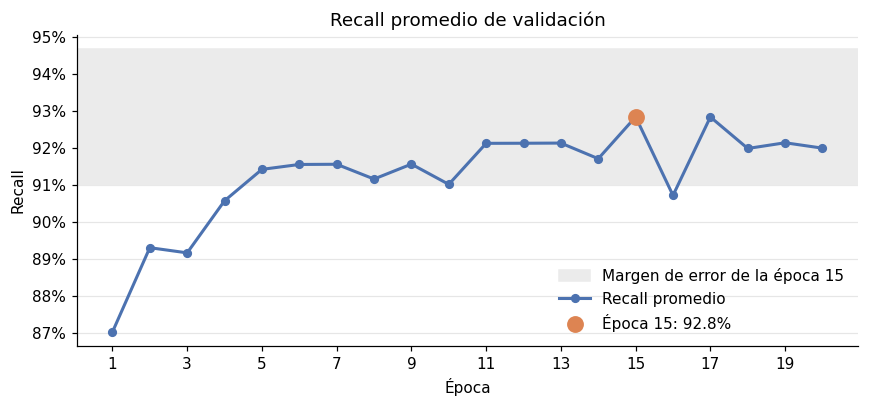

In [9]:
n_val = df_val["clase"].value_counts()
recall_mejor = historial[mejor - 1]["val"]["recall_por_clase"]
# Margen aproximado (95%) del promedio de los 4 recalls, tratados como proporciones independientes.
margen = 1.96 * np.sqrt(sum(recall_mejor[c] * (1 - recall_mejor[c]) / n_val[c] for c in CLASES)) / len(CLASES)
valor = curvas.loc[mejor, "recall val"]
print(f"Recall de la época {mejor}: {valor:.1%} (margen aproximado: ±{margen:.1%})")
dentro = curvas.loc[5:, "recall val"] >= valor - margen
print(f"Épocas 5 a {len(curvas)} dentro de ese margen: {dentro.sum()} de {len(dentro)}")
print(f"Rango desde la época 5: {curvas.loc[5:, 'recall val'].min():.1%} a {curvas.loc[5:, 'recall val'].max():.1%}")
print(f"Época con menor loss de validación: {curvas['loss val'].idxmin()}")

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.axhspan(valor - margen, valor + margen, color="0.92", label="Margen de error de la época 15")
ax.plot(curvas["recall val"], color=AZUL, linewidth=2, marker="o", markersize=5, label="Recall promedio")
ax.plot(mejor, valor, marker="o", markersize=10, color=NARANJA, linestyle="none", label=f"Época {mejor}: {valor:.1%}")
estilo(ax, "Recall promedio de validación", "Recall")
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1, decimals=0))
ax.legend(frameon=False, loc="lower right")
plt.tight_layout()
plt.show()

**Lectura.** La época 15 es la mejor, pero por poco: 15 de las 16 épocas posteriores a la 4
quedan dentro de su margen de error (±1,8 puntos), y la 17 tiene un recall casi idéntico y una
loss de validación menor. La única que queda afuera es la 16 (90,7%).

La conclusión es que el modelo llega a una meseta alrededor del 92%, y no que la época 15 sea
significativamente superior. El margen es aproximado: supone que los recalls por clase son
independientes y no considera que todas las épocas se miden sobre las mismas imágenes.

Además, el 16,8% de las imágenes de validación tiene una copia casi idéntica en train (ver la
sección 3), por lo que estos valores son levemente optimistas.

### 2.3 Glioma y meningioma compiten entre sí

El promedio es estable, pero oculta un movimiento entre dos clases.

Cambios de época en sentidos opuestos: 15 de 19
Correlación entre ambos recalls: -0.67


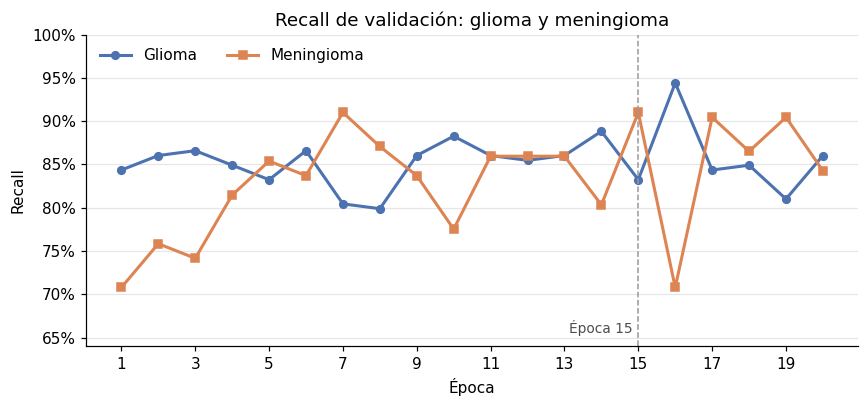

In [10]:
cambio_glioma, cambio_meningioma = np.diff(curvas["glioma"]), np.diff(curvas["meningioma"])
opuestos = (cambio_glioma * cambio_meningioma < 0).sum()
print(f"Cambios de época en sentidos opuestos: {opuestos} de {len(cambio_glioma)}")
print(f"Correlación entre ambos recalls: {np.corrcoef(curvas['glioma'], curvas['meningioma'])[0, 1]:.2f}")

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(curvas["glioma"], color=AZUL, linewidth=2, marker="o", markersize=5, label="Glioma")
ax.plot(curvas["meningioma"], color=NARANJA, linewidth=2, marker="s", markersize=5, label="Meningioma")
ax.axvline(mejor, color="0.6", linewidth=1, linestyle="--")
ax.annotate(f"Época {mejor}", (mejor, 0.655), xytext=(-4, 0), textcoords="offset points", ha="right", fontsize=9, color="0.3")
estilo(ax, "Recall de validación: glioma y meningioma", "Recall")
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1, decimals=0))
ax.set_ylim(0.64, 1)
ax.legend(frameon=False, loc="upper left", ncols=2)
plt.tight_layout()
plt.show()

**Lectura.** En 15 de 19 cambios de época, cuando mejora una clase empeora la otra. El caso más
claro es la época 16: glioma sube a 94,4% y meningioma cae a 70,8%. Es compatible con que el
modelo mueva el límite entre dos clases que le resultan parecidas: al favorecer a una,
perjudica a la otra. Esta sección solo muestra la oscilación; la confusión entre ambas se
comprueba con la matriz de test (ver `docs/model_card.md`).

También muestra una consecuencia de elegir por el promedio: en la época 15 meningioma tiene
91,0% y glioma 83,2%. Otra época con un promedio similar habría repartido los errores de otra
manera.

---
## 3. La evaluación

El conjunto de **test** no se usa para entrenar ni para elegir la época. Responde una sola
pregunta: si llega una imagen nueva, ¿el modelo acierta?

### 3.1 Qué imágenes de test no son realmente nuevas

El deduplicado del proyecto elimina archivos idénticos, pero no detecta la misma imagen guardada
con otro contraste o nitidez. Como la división es al azar, la original pudo quedar en train y su
copia en test. Busco, para cada imagen de test, la más parecida de train (correlación entre
imágenes reducidas a 32×32).

In [11]:
vectores_train = vectores_de_comparacion(df_train["path"])
similitudes = vectores_de_comparacion(df_test["path"]) @ vectores_train.T
similitud, mas_parecida = similitudes.max(axis=1), similitudes.argmax(axis=1)
es_copia = similitud >= UMBRAL_COPIA

print(f"Test con copia en train: {es_copia.sum()} de {len(df_test)} ({es_copia.mean():.1%})")
pd.crosstab(df_test["clase"], np.where(es_copia, "con copia", "nuevas")).loc[list(CLASES)]

Test con copia en train: 257 de 1403 (18.3%)


col_0,con copia,nuevas
clase,,
glioma,3,354
meningioma,32,325
pituitary,1,352
notumor,221,115


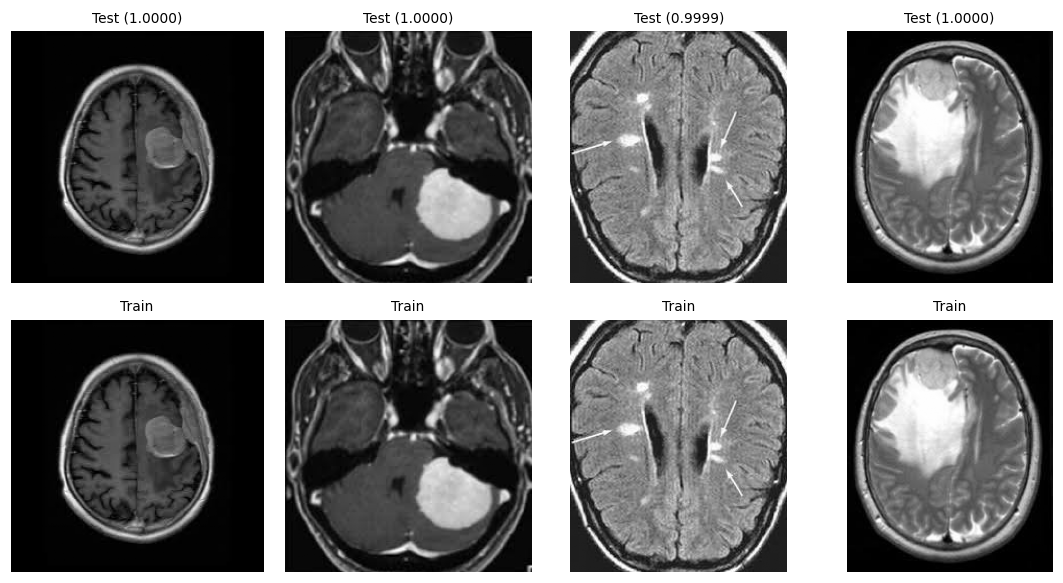

In [12]:
ejemplos = np.random.default_rng(42).choice(np.flatnonzero(es_copia), 4, replace=False)
fig, ax = plt.subplots(2, 4, figsize=(10, 5.4))
for col, i in enumerate(ejemplos):
    for fila, (path, titulo) in enumerate(
        [(df_test["path"].iloc[i], "Test"), (df_train["path"].iloc[mas_parecida[i]], "Train")]
    ):
        ax[fila, col].imshow(Image.open(path).convert("L"), cmap="gray")
        ax[fila, col].set_title(f"{titulo} ({similitud[i]:.4f})" if fila == 0 else titulo, fontsize=9)
        ax[fila, col].axis("off")
plt.tight_layout()
plt.show()

**Lectura.** El 18,3% del test tiene una copia en train, y 221 de las 257 son de la clase sin
tumor. En los ejemplos, test y train muestran el mismo corte. Estas imágenes quedan fuera de la
evaluación: acertarlas no demuestra que el modelo generalice.

Es un criterio por contenido y no detecta cortes distintos de un mismo paciente, dato que el
dataset no informa.

### 3.2 Resultados sobre las imágenes nuevas

Corro el modelo sobre todo el test y calculo las métricas solo con las imágenes sin copia. El
**recall** de una clase es la proporción de sus imágenes que el modelo reconoce; la
**precisión**, la proporción de aciertos cuando el modelo responde esa clase.

In [13]:
loader_test = DataLoader(MRIDataset(df_test, get_eval_pipeline()), batch_size=64)
y_true, y_pred, y_proba = predecir(model, loader_test)

nuevas = ~es_copia
m = compute_metrics(y_true[nuevas], y_pred[nuevas], y_proba[nuevas])
print(f"Imágenes: {nuevas.sum()} | recall promedio: {m['recall_macro']:.1%} | ROC-AUC: {m['roc_auc_macro']:.3f}")
print(f"Tumores predichos como sin tumor: {m['tumores_como_sanos']} de {m['tumores_total']} ({m['tumores_como_sanos'] / m['tumores_total']:.1%})")

tabla = pd.DataFrame(m["por_clase"]).T.rename(index=eda.ETIQUETAS)
tabla["margen recall"] = 1.96 * np.sqrt(tabla["recall"] * (1 - tabla["recall"]) / tabla["soporte"])
tabla.round(3)

Imágenes: 1146 | recall promedio: 92.5% | ROC-AUC: 0.987
Tumores predichos como sin tumor: 13 de 1031 (1.3%)


,recall,precision,f1,soporte,roc_auc,margen recall
Glioma,0.867,0.968,0.915,354.0,0.984,0.035
Meningioma,0.914,0.837,0.874,325.0,0.974,0.031
Pituitario,0.955,0.960,0.957,352.0,0.997,0.022
Sin tumor,0.965,0.895,0.929,115.0,0.994,0.033


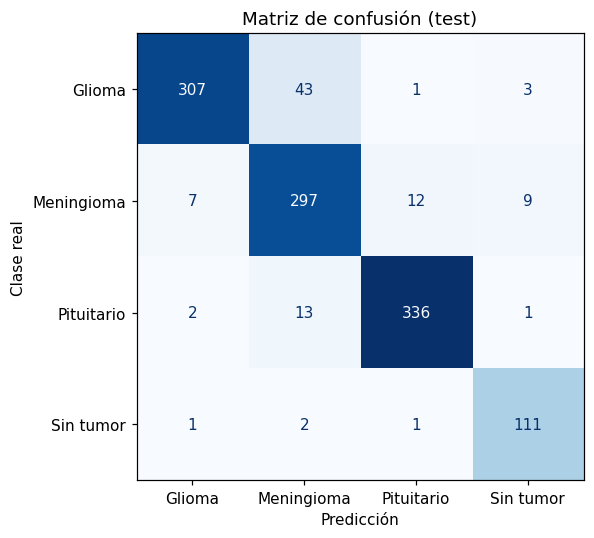

In [14]:
fig = plot_confusion_matrix(y_true[nuevas], y_pred[nuevas], [eda.ETIQUETAS[c] for c in CLASES])
plt.show()

**Lectura.** El recall promedio es 92,5%. El tipo de error se distribuye de manera muy desigual:

- **El más frecuente** es glioma predicho como meningioma (43 casos). El tumor se detecta, pero
  no su tipo.
- **El más grave** es un tumor predicho como sin tumor (13 de 1.031). La sección 4 muestra que no
  se reparte al azar.
- **La precisión de "sin tumor" (89,5%)** es baja en parte por la composición: quedan 115 imágenes
  de esa clase contra más de 300 de las otras, y unos pocos tumores mal clasificados pesan más.

El margen del recall de "sin tumor" es de ±3,3 puntos, por tener menos imágenes.

### 3.3 Cuánto influye la exclusión

In [15]:
copias_notumor = es_copia & (y_true == CLASES.index("notumor"))
nuevas_notumor = nuevas & (y_true == CLASES.index("notumor"))
for nombre, mascara in (("con copia en train", copias_notumor), ("nuevas", nuevas_notumor)):
    aciertos = (y_pred[mascara] == y_true[mascara]).sum()
    print(f"Sin tumor, {nombre}: {aciertos} de {mascara.sum()} ({aciertos / mascara.sum():.1%})")

sensibilidad_al_umbral(y_true, y_pred, similitud).round(3)

Sin tumor, con copia en train: 221 de 221 (100.0%)
Sin tumor, nuevas: 111 de 115 (96.5%)


,umbral,imagenes,recall_macro,recall_glioma,recall_meningioma,recall_pituitary,recall_notumor,n_notumor,tumores_como_sanos,tumores_total
0,0.98,997,0.918,0.857,0.914,0.954,0.947,57,13,940
1,0.99,1099,0.923,0.865,0.913,0.955,0.961,76,13,1023
2,0.995,1128,0.924,0.867,0.913,0.955,0.960,99,13,1029
3,0.999,1146,0.925,0.867,0.914,0.955,0.965,115,13,1031
4,sin excluir,1403,0.930,0.866,0.916,0.952,0.988,336,14,1067


**Lectura.** El modelo acierta todas las imágenes sin tumor que tienen copia en train y el 96,5%
de las nuevas. Incluirlas elevaba el recall de esa clase a 98,8% y el promedio a 93,0%.

Cuanto más estricto es el criterio, más baja el promedio, hasta 91,8%. Elegí 0,999 conociendo
estos resultados, por lo que informo la tabla completa. El número de tumores predichos como sin
tumor no cambia con el umbral.

---
## 4. Los errores

Las métricas dicen cuánto falla el modelo, pero no en qué. Esta sección mira las imágenes.

### 4.1 ¿El modelo falla con seguridad o con dudas?

In [16]:
errores = df_test.assign(
    prediccion=[CLASES[i] for i in y_pred],
    seguridad=y_proba.max(axis=1),
    acierto=y_true == y_pred,
    lado=[min(Image.open(p).size) for p in df_test["path"]],
)[nuevas].reset_index(drop=True)
proba_nuevas = y_proba[nuevas]

rangos = pd.cut(errores["seguridad"], [0, 0.5, 0.7, 0.9, 1.0], labels=["hasta 50%", "50 a 70%", "70 a 90%", "más de 90%"])
resumen = errores.groupby(rangos, observed=True)["acierto"].agg(imágenes="count", aciertos="sum")
resumen["errores"] = resumen["imágenes"] - resumen["aciertos"]
resumen["% de aciertos"] = (resumen["aciertos"] / resumen["imágenes"] * 100).round(1)
print(f"Errores totales: {(~errores['acierto']).sum()}")
resumen

Errores totales: 95


,imágenes,aciertos,errores,% de aciertos
seguridad,,,,
hasta 50%,28,15,13,53.6
50 a 70%,136,97,39,71.3
70 a 90%,248,216,32,87.1
más de 90%,734,723,11,98.5


**Lectura.** La seguridad del modelo es informativa: por encima de 90% acierta el 98,5%, y por
debajo de 50% apenas la mitad. Una aplicación real podría derivar a revisión los casos dudosos.

No es una garantía: 11 errores tienen una seguridad mayor al 90%. Además, estos porcentajes se
midieron sobre test y solo describen; para fijar un umbral habría que usar validación.

### 4.2 Tumores predichos como "Sin tumor"

Es el error más grave. Muestro todos, con la probabilidad que el modelo asignó a "Sin
tumor".

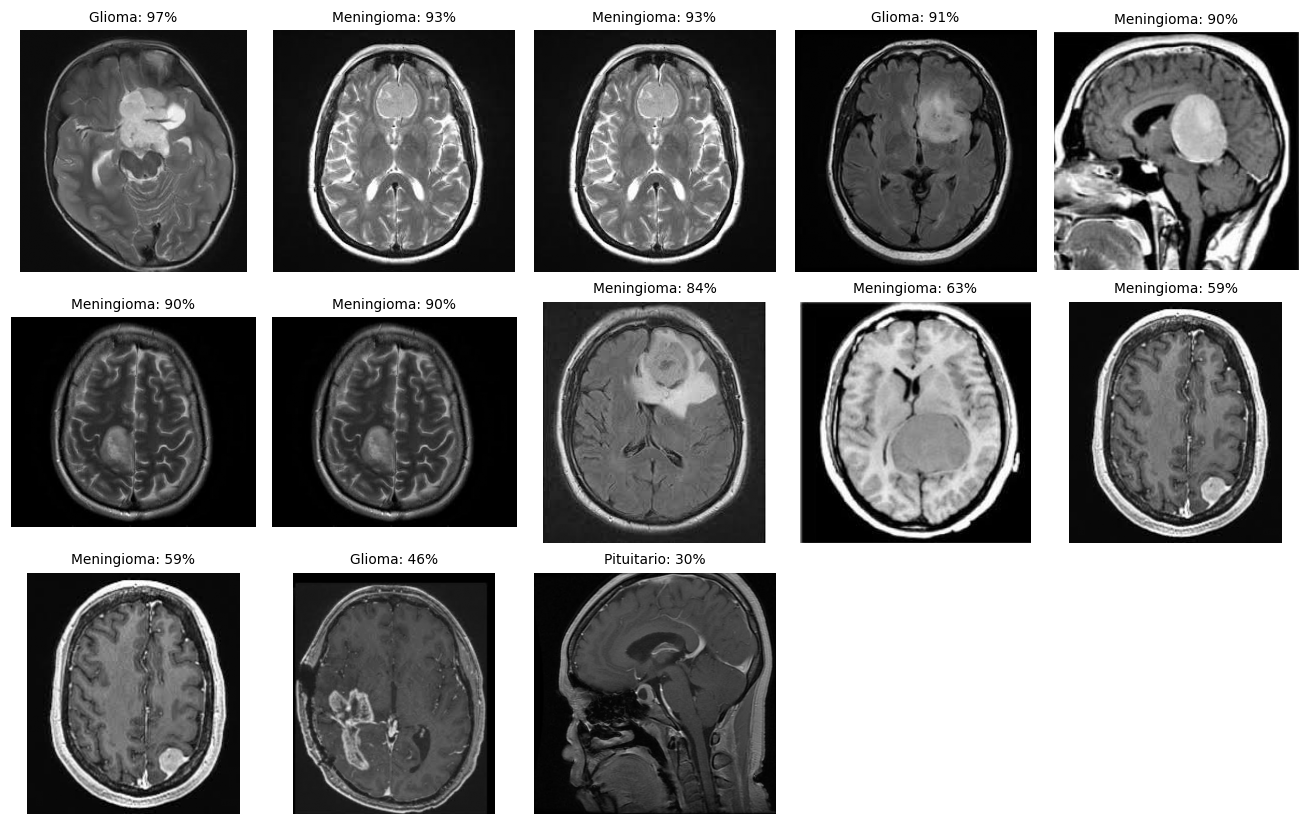

In [17]:
graves = errores[(errores["clase"] != "notumor") & (errores["prediccion"] == "notumor")]
graves = graves.sort_values("seguridad", ascending=False)

fig, ax = plt.subplots(3, 5, figsize=(12, 7.6))
for a, r in zip(ax.flat, graves.itertuples()):
    a.imshow(Image.open(r.path).convert("L"), cmap="gray")
    a.set_title(f"{eda.ETIQUETAS[r.clase]}: {r.seguridad:.0%}", fontsize=9)
for a in ax.flat:
    a.axis("off")
plt.tight_layout()
plt.show()

In [18]:
vectores_graves = vectores_de_comparacion(graves["path"])
repetidas = np.triu(vectores_graves @ vectores_graves.T >= UMBRAL_COPIA, k=1).any(axis=0).sum()
print(f"Tumores predichos como sin tumor: {len(graves)} | imágenes distintas: {len(graves) - repetidas}")

Tumores predichos como sin tumor: 13 | imágenes distintas: 10


**Lectura.** Son 13 imágenes, pero 10 distintas: tres aparecen repetidas. En la mayoría la lesión
es grande y visible, por lo que no parecen errores por casos sutiles.

A simple vista, varias no tienen el aspecto de T1 con contraste de la mayoría de los tumores del
dataset: el líquido cefalorraquídeo o la lesión aparecen brillantes, como en T2 o FLAIR. Es una
apreciación visual mía, sin confirmación médica.

### 4.3 El tamaño de la imagen como indicio de la fuente

El modelo no conoce el tamaño original, porque toda imagen se lleva a 224×224. Pero en este
dataset el tamaño acompaña a la fuente de origen. Separo las imágenes en dos grupos.

In [19]:
errores["tamaño"] = np.where(errores["lado"] < 300, "menos de 300 px", "300 px o más")
errores["como_sano"] = errores["prediccion"] == "notumor"
por_tamaño = errores.groupby(["clase", "tamaño"]).agg(
    imágenes=("acierto", "size"), recall=("acierto", "mean"), predichas_sin_tumor=("como_sano", "sum")
)

tumores = errores[errores["clase"] != "notumor"]
for tamaño, d in tumores.groupby("tamaño"):
    print(f"Tumores de {tamaño}: {d['como_sano'].sum()} de {len(d)} predichos como sin tumor ({d['como_sano'].mean():.1%})")
print("\nProporción de imágenes de exactamente 512 px:")
print(errores.assign(es_512=errores["lado"] == 512).groupby("clase")["es_512"].mean().round(3).to_string())
por_tamaño.round(3)

Tumores de 300 px o más: 3 de 1008 predichos como sin tumor (0.3%)
Tumores de menos de 300 px: 10 de 23 predichos como sin tumor (43.5%)

Proporción de imágenes de exactamente 512 px:
clase
glioma        0.972
meningioma    0.932
notumor       0.000
pituitary     0.983


imágenes  recall  predichas_sin_tumor
clase      tamaño                                                
glioma     300 px o más          352   0.872                    2
           menos de 300 px         2   0.000                    1
meningioma 300 px o más          309   0.939                    0
           menos de 300 px        16   0.438                    9
notumor    300 px o más           32   0.969                   31
           menos de 300 px        83   0.964                   80
pituitary  300 px o más          347   0.954                    1
           menos de 300 px         5   1.000                    0

**Lectura.** Este es el hallazgo más importante sobre el modelo:

- **De los tumores de menos de 300 px, 10 de 23 se predicen como sin tumor (43,5%). De los de
  300 px o más, 3 de 1.008 (0,3%).** El 1,3% general oculta esa diferencia.
- **El tamaño casi identifica la clase.** Entre el 93% y el 98% de las imágenes con tumor mide
  exactamente 512 px; ninguna imagen sin tumor lo hace.

Es compatible con el atajo sospechado desde el EDA: los tumores con aspecto similar al de las
imágenes sin tumor se confunden con ellas. El 1,3% vale sobre todo para imágenes como las de la
fuente principal, y no puede trasladarse a otras.

**Alcance.** Es una asociación y no prueba la causa: el tamaño, la fuente y la secuencia varían
juntos. Hay pocos casos (23, con imágenes repetidas), por lo que el 43,5% es muy impreciso:
aproximadamente entre 26% y 63%. El modelo tampoco responde solo al tamaño: reconoce 31 de las
32 imágenes sin tumor de 300 px o más.

### 4.4 Gliomas predichos como meningioma

Es el error más frecuente. Muestro 8 elegidos al azar (semilla fija).

Gliomas predichos como meningioma: 43 | con glioma como segunda opción: 39
Seguridad mediana: 71% | con más de 90%: 4


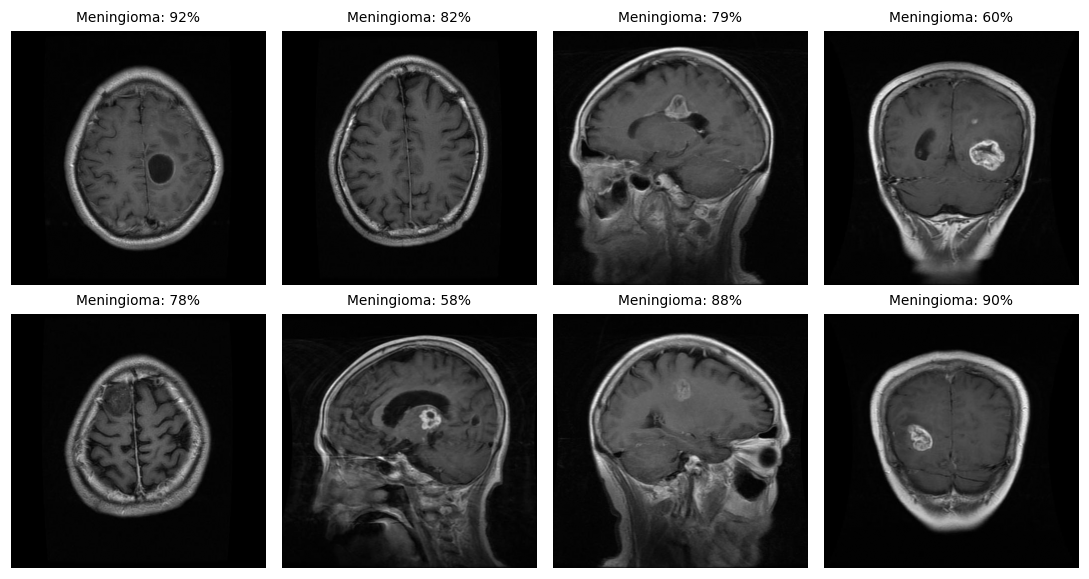

In [20]:
i_glioma = CLASES.index("glioma")
confundidos = errores[(errores["clase"] == "glioma") & (errores["prediccion"] == "meningioma")]
segunda = np.argsort(proba_nuevas[confundidos.index], axis=1)[:, -2]
print(f"Gliomas predichos como meningioma: {len(confundidos)} | con glioma como segunda opción: {(segunda == i_glioma).sum()}")
print(f"Seguridad mediana: {confundidos['seguridad'].median():.0%} | con más de 90%: {(confundidos['seguridad'] > 0.9).sum()}")

fig, ax = plt.subplots(2, 4, figsize=(10, 5.4))
for a, r in zip(ax.flat, confundidos.sample(8, random_state=42).itertuples()):
    a.imshow(Image.open(r.path).convert("L"), cmap="gray")
    a.set_title(f"Meningioma: {r.seguridad:.0%}", fontsize=9)
    a.axis("off")
plt.tight_layout()
plt.show()

**Lectura.** En 39 de los 43 casos, glioma es la segunda opción: el modelo duda justamente entre
esas dos clases. La seguridad mediana es de 71%, y solo 4 superan el 90%. Por eso el endpoint
devuelve las 4 probabilidades y no solo la clase ganadora.

No atribuyo una causa visual: reconocer por qué estos gliomas se parecen a meningiomas requiere
criterio médico.

---
## 5. La prueba de brillo

El EDA mostró que las imágenes sin tumor son más brillantes que las de glioma, una diferencia que
proviene de la fuente y no de la patología. Si el modelo usara el brillo como atajo:

- **aclarar** una imagen con tumor haría que la predijera como sin tumor;
- **oscurecer** una imagen sin tumor haría que dejara de reconocerla.

Multiplico el brillo de las imágenes de test sin copia por distintos factores. El modelo ya vio
variaciones de 0,6 a 1,4 al entrenar, por lo que lo más informativo es lo que ocurre afuera de
ese rango.

In [21]:
df_nuevas = df_test[nuevas].reset_index(drop=True)
estres = brightness_stress_test(model, df_nuevas)

n_tumor = (df_nuevas["clase"] != "notumor").sum()
n_sano = len(df_nuevas) - n_tumor
estres["tumores como sanos (n)"] = (estres["tumores_como_sanos"] * n_tumor).round().astype(int)
estres["sanos reconocidos (n)"] = (estres["recall_notumor"] * n_sano).round().astype(int)
print(f"Tumores: {n_tumor} | sin tumor: {n_sano}")
estres.round(3)

Tumores: 1031 | sin tumor: 115


,factor,tumores_como_sanos,recall_notumor,accuracy,tumores como sanos (n),sanos reconocidos (n)
0,0.50,0.013,0.922,0.903,13,106
1,0.75,0.014,0.957,0.920,14,110
2,1.00,0.013,0.965,0.917,13,111
3,1.25,0.016,0.957,0.906,16,110
4,1.50,0.022,0.965,0.895,23,111
5,1.80,0.032,0.965,0.877,33,111


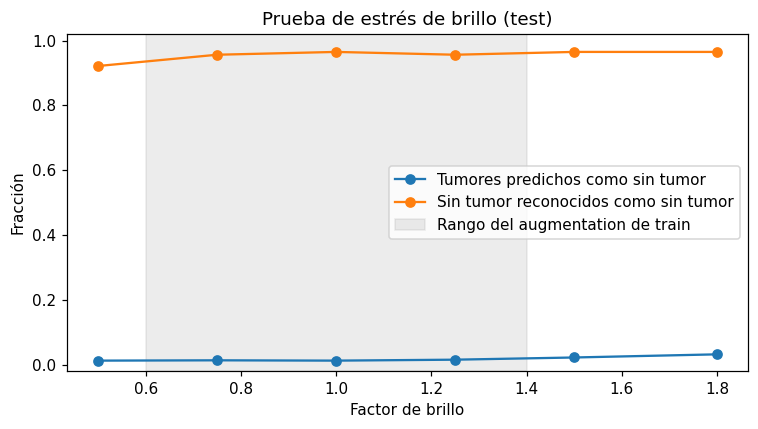

In [22]:
fig = plot_brightness_stress_test(estres)
plt.show()

**Lectura.** El brillo no es la señal principal. Con las imágenes sin tumor a la mitad de su
brillo, el modelo reconoce 106 de 115, contra 111 con el brillo original. Al aclarar los tumores
hasta 1,8, los predichos como sin tumor pasan de 13 a 33 de 1.031.

Existe una sensibilidad leve fuera del rango de entrenamiento. Parte puede deberse a que aclarar
tanto satura píxeles en blanco y degrada la imagen.

**La prueba no descarta otros atajos.** Solo modifica el brillo global. La sección 4.3 mostró una
diferencia mucho mayor asociada al tamaño de la imagen, que en este dataset acompaña a la fuente y,
posiblemente, a la secuencia. Separar esos factores requiere que un profesional identifique la
secuencia de cada imagen.